In [1]:
# Import the libraries required for dataset inspection and model evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

print("Notebook 05 environment initialized successfully.")

Notebook 05 environment initialized successfully.


In [2]:
# Load the LLM-authored financial scam dataset

DATA_PATH = Path("../data/processed/llm_authored_financial_scams_processed.csv")

df_llm = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df_llm.shape}")
print(f"\nTotal records: {len(df_llm):,}")
print("\nColumns:")
print(df_llm.columns.tolist())

print("\nPartition distribution:")
print(df_llm["split_partition"].value_counts(dropna=False))

Dataset shape: (2730, 45)

Total records: 2,730

Columns:
['id', 'text', 'label', 'phishing_type', 'scam_channel', 'fraudulent_intent', 'social_engineering_tactics', 'primary_intent_evidence', 'primary_intent_start', 'primary_intent_end', 'tactics_evidence', 'writing_style', 'email_subject', 'optional_scenario_description', 'urgency_rating', 'secondary_channel_source', 'scenario_family', 'synthetic', 'generation_method', 'model_provenance', 'language', 'original_text', 'normalized_text', 'char_count_original', 'word_count_original', 'char_count_normalized', 'word_count_normalized', 'placeholder_count_original', 'placeholder_count_normalized', 'placeholder_density', 'duplicate_cluster_id', 'split_partition', 'record_id', 'scam_subtype', 'channel', 'original_channel', 'is_email_gateway', 'has_gateway_headers', 'source', 'source_url', 'source_license', 'source_record_id', 'is_synthetic', 'legitimate_category', 'email_body']

Partition distribution:
split_partition
train    2184
val       

In [3]:
# Inspect label distributions, missing values, and partition-level coverage

print("SCAM SUBTYPE DISTRIBUTION")
display(df_llm["scam_subtype"].value_counts())

print("\nFRAUDULENT INTENT DISTRIBUTION")
display(df_llm["fraudulent_intent"].value_counts())

print("\nWRITING STYLE DISTRIBUTION")
display(df_llm["writing_style"].value_counts())

print("\nCHANNEL DISTRIBUTION")
display(df_llm["channel"].value_counts())

print("\nMISSING VALUES")
missing = df_llm.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))

print("\nPARTITION × SUBTYPE")
display(pd.crosstab(df_llm["split_partition"], df_llm["scam_subtype"]))

SCAM SUBTYPE DISTRIBUTION


scam_subtype
account_verification              210
card_transaction_alert            210
refund_chargeback                 210
invoice_payment_request           210
loan_offer                        210
investment_crypto                 210
prize_reward                      210
tax_payment                       210
job_task_commission               210
romance_financial_manipulation    210
family_emergency_request          210
recovery_support                  210
charity_donation                  210
Name: count, dtype: int64


FRAUDULENT INTENT DISTRIBUTION


fraudulent_intent
induce_payment_or_transfer                  1247
obtain_credentials_or_codes                  582
obtain_personal_or_financial_information     506
gain_account_or_device_access                228
induce_fraudulent_investment                 167
Name: count, dtype: int64


WRITING STYLE DISTRIBUTION


writing_style
casual_informal            390
direct_terse               390
conversational_personal    390
professional_neutral       390
corporate_institutional    390
sophisticated_formal       390
dialogue_interactive       390
Name: count, dtype: int64

... (2 outputs left out)


MISSING VALUES


duplicate_cluster_id             2730
legitimate_category              2730
email_subject                    1585
secondary_channel_source          423
optional_scenario_description     403
urgency_rating                    382
dtype: int64


PARTITION × SUBTYPE


scam_subtype,account_verification,card_transaction_alert,charity_donation,family_emergency_request,investment_crypto,invoice_payment_request,job_task_commission,loan_offer,prize_reward,recovery_support,refund_chargeback,romance_financial_manipulation,tax_payment
split_partition,,,,,,,,,,,,,
test,21,21,21,21,21,21,21,21,21,21,21,21,21
train,168,168,168,168,168,168,168,168,168,168,168,168,168
val,21,21,21,21,21,21,21,21,21,21,21,21,21


In [4]:
# Verify compatible dataset fields and identify records eligible for tactic evaluation

consistency_checks = {
    "text vs original_text": (df_llm["text"] == df_llm["original_text"]).all(),
    "phishing_type vs scam_subtype": (df_llm["phishing_type"] == df_llm["scam_subtype"]).all(),
    "scam_channel vs channel": (df_llm["scam_channel"] == df_llm["channel"]).all(),
    "label contains only scam class": df_llm["label"].nunique() == 1,
}

print("FIELD CONSISTENCY")
for field, result in consistency_checks.items():
    print(f"{field}: {result}")

print("\nTACTIC ANNOTATION COVERAGE")
tactic_annotated = df_llm["social_engineering_tactics"].notna() & (
    df_llm["social_engineering_tactics"].astype(str).str.strip() != ""
)

print(f"Annotated records: {tactic_annotated.sum():,}")
print(f"Unannotated records: {(~tactic_annotated).sum():,}")

print("\nTACTIC COVERAGE BY PARTITION")
display(
    df_llm.assign(tactic_annotated=tactic_annotated)
    .groupby("split_partition")["tactic_annotated"]
    .agg(["sum", "count"])
)

FIELD CONSISTENCY
text vs original_text: True
phishing_type vs scam_subtype: True
scam_channel vs channel: True
label contains only scam class: True

TACTIC ANNOTATION COVERAGE
Annotated records: 2,730
Unannotated records: 0

TACTIC COVERAGE BY PARTITION


,sum,count
split_partition,,
test,273,273
train,2184,2184
val,273,273


In [5]:
# Inspect the stored formats of subtype, intent, and tactic annotations

print("DATA TYPES")
print(df_llm[
    ["scam_subtype", "fraudulent_intent", "social_engineering_tactics"]
].dtypes)

print("\nSAMPLE ANNOTATIONS")
for column in ["scam_subtype", "fraudulent_intent", "social_engineering_tactics"]:
    print(f"\n{column}:")
    for value in df_llm[column].head(3):
        print(repr(value))

print("\nTACTIC LABEL FREQUENCIES")
display(
    df_llm["social_engineering_tactics"]
    .explode()
    .value_counts()
)

DATA TYPES
scam_subtype                  str
fraudulent_intent             str
social_engineering_tactics    str
dtype: object

SAMPLE ANNOTATIONS

scam_subtype:
'account_verification'
'account_verification'
'account_verification'

fraudulent_intent:
'obtain_credentials_or_codes'
'obtain_credentials_or_codes'
'obtain_personal_or_financial_information'

social_engineering_tactics:
'["urgency", "fear_or_threat", "false_legitimacy"]'
'["urgency", "fear_or_threat", "authority_impersonation"]'
'["trust_exploitation", "emotional_manipulation", "false_legitimacy"]'

TACTIC LABEL FREQUENCIES


social_engineering_tactics
["false_legitimacy", "reward_or_benefit"]                                       116
["authority_impersonation", "fear_or_threat", "urgency", "false_legitimacy"]     98
["urgency", "fear_or_threat", "false_legitimacy"]                                96
["authority_impersonation", "fear_or_threat", "urgency"]                         73
["urgency", "reward_or_benefit", "false_legitimacy"]                             63
                                                                               ... 
["scarcity", "urgency", "trust_exploitation", "false_legitimacy"]                 1
["false_legitimacy", "urgency", "emotional_manipulation"]                         1
["authority_impersonation", "false_legitimacy", "secrecy"]                        1
["urgency", "scarcity", "authority_impersonation"]                                1
["false_legitimacy", "trust_exploitation", "scarcity"]                            1
Name: count, Length: 400, dtype: int64

In [6]:
# Parse JSON-formatted tactic annotations into Python lists

import json

df_llm["tactics_list"] = df_llm["social_engineering_tactics"].apply(json.loads)

print("TACTIC LABEL FREQUENCIES")
tactic_counts = df_llm["tactics_list"].explode().value_counts()
display(tactic_counts)

print("\nTACTIC CARDINALITY PER RECORD")
display(df_llm["tactics_list"].apply(len).value_counts().sort_index())

print(f"\nTotal distinct tactics: {len(tactic_counts)}")
print(f"Total tactic annotations: {tactic_counts.sum():,}")

TACTIC LABEL FREQUENCIES


tactics_list
false_legitimacy           1857
urgency                    1743
reward_or_benefit          1046
authority_impersonation     971
fear_or_threat              883
trust_exploitation          802
emotional_manipulation      554
scarcity                    300
secrecy                      40
Name: count, dtype: int64


TACTIC CARDINALITY PER RECORD


tactics_list
1       6
2     465
3    1776
4     483
Name: count, dtype: int64


Total distinct tactics: 9
Total tactic annotations: 8,196


In [7]:
# Verify the original processed datasets required to reproduce Notebook 04 baselines

V3_PATH = Path("../data/processed/synthetic_financial_scams_v3_corrected_processed.csv")
V31_PATH = Path("../data/processed/synthetic_financial_scams_v3_1_processed.csv")

print("V3 dataset exists:", V3_PATH.exists())
print("V3.1 dataset exists:", V31_PATH.exists())

if V3_PATH.exists():
    print("V3 size:", pd.read_csv(V3_PATH, usecols=["split_partition"]).shape[0])

if V31_PATH.exists():
    print("V3.1 size:", pd.read_csv(V31_PATH, usecols=["split_partition"]).shape[0])

V3 dataset exists: True
V3.1 dataset exists: True
V3 size: 7800
V3.1 size: 7800


In [8]:
# Load the original V3 and V3.1 datasets and isolate their training partitions

df_v3 = pd.read_csv(V3_PATH)
df_v31 = pd.read_csv(V31_PATH)

train_v3 = df_v3[df_v3["split_partition"] == "train"].copy()
train_v31 = df_v31[df_v31["split_partition"] == "train"].copy()

print(f"V3 training records: {len(train_v3):,}")
print(f"V3.1 training records: {len(train_v31):,}")

print("\nV3 subtype classes:", train_v3["scam_subtype"].nunique())
print("V3.1 intent classes:", train_v31["fraudulent_intent"].nunique())

V3 training records: 6,240
V3.1 training records: 6,240

V3 subtype classes: 13
V3.1 intent classes: 5


In [9]:
# Reproduce the Notebook 04 subtype baseline using only V3 training data

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

subtype_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

subtype_model.fit(
    train_v3["normalized_text"],
    train_v3["scam_subtype"]
)

print("Original subtype baseline reproduced.")
print(f"Training records: {len(train_v3):,}")
print(f"TF-IDF vocabulary size: {len(subtype_model.named_steps['tfidf'].vocabulary_):,}")

Original subtype baseline reproduced.
Training records: 6,240
TF-IDF vocabulary size: 11,970


In [10]:
# Evaluate the original subtype classifier on unseen LLM-authored narratives

llm_test = df_llm[df_llm["split_partition"] == "test"].copy()

y_subtype_true = llm_test["scam_subtype"]
y_subtype_pred = subtype_model.predict(llm_test["normalized_text"])

subtype_accuracy = accuracy_score(y_subtype_true, y_subtype_pred)
subtype_macro_f1 = f1_score(y_subtype_true, y_subtype_pred, average="macro")
subtype_weighted_f1 = f1_score(y_subtype_true, y_subtype_pred, average="weighted")

print(f"Evaluation records: {len(llm_test)}")
print(f"Accuracy:           {subtype_accuracy:.4f}")
print(f"Macro-F1:           {subtype_macro_f1:.4f}")
print(f"Weighted-F1:        {subtype_weighted_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_subtype_true,
    y_subtype_pred,
    zero_division=0
))

Evaluation records: 273
Accuracy:           0.4505
Macro-F1:           0.4745
Weighted-F1:        0.4745

CLASSIFICATION REPORT
                                precision    recall  f1-score   support

          account_verification       0.22      0.52      0.31        21
        card_transaction_alert       0.63      0.81      0.71        21
              charity_donation       0.82      0.67      0.74        21
      family_emergency_request       0.11      0.29      0.16        21
             investment_crypto       0.63      0.57      0.60        21
       invoice_payment_request       0.85      0.52      0.65        21
           job_task_commission       1.00      0.29      0.44        21
                    loan_offer       0.59      0.48      0.53        21
                  prize_reward       0.92      0.57      0.71        21
              recovery_support       1.00      0.10      0.17        21
             refund_chargeback       0.73      0.52      0.61        21
romance

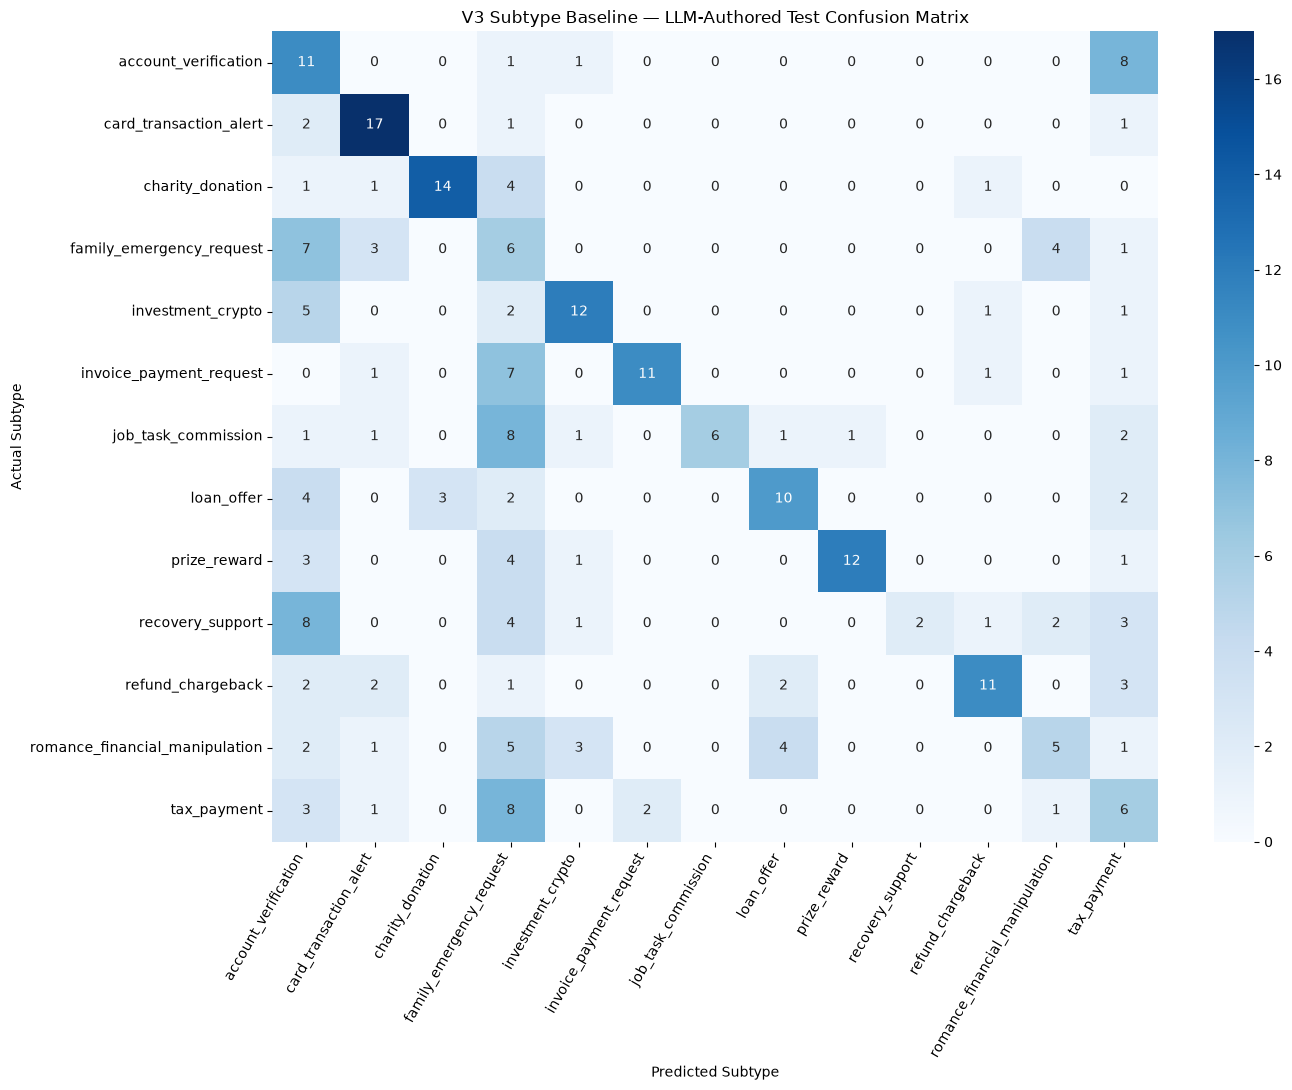

In [11]:
# Visualize subtype misclassification patterns on the LLM-authored test set

subtype_labels = sorted(y_subtype_true.unique())

cm_subtype = confusion_matrix(
    y_subtype_true,
    y_subtype_pred,
    labels=subtype_labels
)

plt.figure(figsize=(14, 11))
sns.heatmap(
    cm_subtype,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=subtype_labels,
    yticklabels=subtype_labels
)

plt.title("V3 Subtype Baseline — LLM-Authored Test Confusion Matrix")
plt.xlabel("Predicted Subtype")
plt.ylabel("Actual Subtype")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Reproduce the Notebook 04 fraudulent intent baseline using V3.1 training data

intent_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

intent_model.fit(
    train_v31["normalized_text"],
    train_v31["fraudulent_intent"]
)

print("Original intent baseline reproduced.")
print(f"Training records: {len(train_v31):,}")
print(f"TF-IDF vocabulary size: {len(intent_model.named_steps['tfidf'].vocabulary_):,}")

Original intent baseline reproduced.
Training records: 6,240
TF-IDF vocabulary size: 13,252


In [13]:
# Evaluate the original fraudulent intent classifier on LLM-authored test data

y_intent_true = llm_test["fraudulent_intent"]
y_intent_pred = intent_model.predict(llm_test["normalized_text"])

intent_accuracy = accuracy_score(y_intent_true, y_intent_pred)
intent_macro_f1 = f1_score(y_intent_true, y_intent_pred, average="macro")
intent_weighted_f1 = f1_score(y_intent_true, y_intent_pred, average="weighted")

print(f"Evaluation records: {len(llm_test)}")
print(f"Accuracy:           {intent_accuracy:.4f}")
print(f"Macro-F1:           {intent_macro_f1:.4f}")
print(f"Weighted-F1:        {intent_weighted_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_intent_true,
    y_intent_pred,
    zero_division=0
))

Evaluation records: 273
Accuracy:           0.6337
Macro-F1:           0.5354
Weighted-F1:        0.6251

CLASSIFICATION REPORT
                                          precision    recall  f1-score   support

           gain_account_or_device_access       0.60      0.35      0.44        17
            induce_fraudulent_investment       1.00      0.19      0.32        21
              induce_payment_or_transfer       0.76      0.74      0.75       118
             obtain_credentials_or_codes       0.48      0.72      0.57        54
obtain_personal_or_financial_information       0.60      0.59      0.59        63

                                accuracy                           0.63       273
                               macro avg       0.69      0.52      0.54       273
                            weighted avg       0.67      0.63      0.63       273



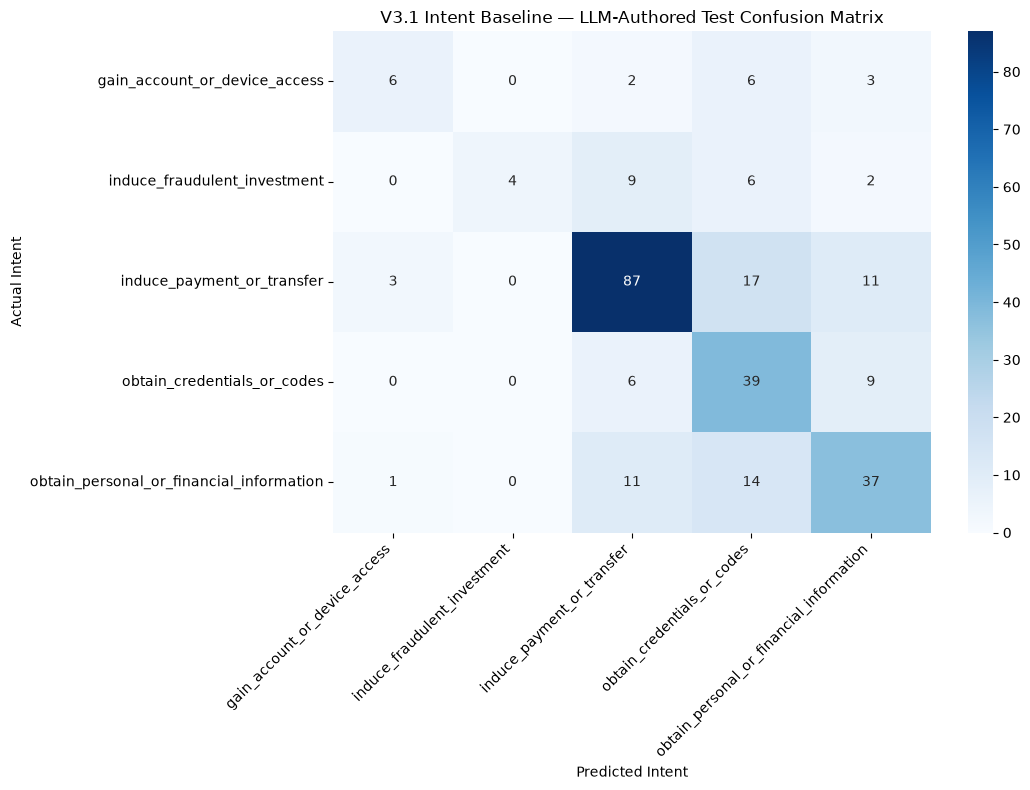

In [14]:
# Visualize fraudulent intent misclassification patterns

intent_labels = sorted(y_intent_true.unique())

cm_intent = confusion_matrix(
    y_intent_true,
    y_intent_pred,
    labels=intent_labels
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    cm_intent,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_labels,
    yticklabels=intent_labels
)

plt.title("V3.1 Intent Baseline — LLM-Authored Test Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
# Reproduce the Notebook 04 multilabel tactic classifier using V3.1 training data

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier

train_tactics = train_v31[
    train_v31["social_engineering_tactics"].notna()
].copy()

train_tactics["tactics_list"] = train_tactics["social_engineering_tactics"].apply(json.loads)

mlb = MultiLabelBinarizer()
Y_tactic_train = mlb.fit_transform(train_tactics["tactics_list"])

tactic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", OneVsRestClassifier(
        LogisticRegression(
            C=1,
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    ))
])

tactic_model.fit(
    train_tactics["normalized_text"],
    Y_tactic_train
)

print("Original tactic baseline reproduced.")
print(f"Training records: {len(train_tactics):,}")
print(f"Number of tactic labels: {len(mlb.classes_)}")
print(f"TF-IDF vocabulary size: {len(tactic_model.named_steps['tfidf'].vocabulary_):,}")
print("\nTactic classes:")
print(mlb.classes_)

Original tactic baseline reproduced.
Training records: 6,240
Number of tactic labels: 9
TF-IDF vocabulary size: 13,252

Tactic classes:
['authority_impersonation' 'emotional_manipulation' 'false_legitimacy'
 'fear_or_threat' 'reward_or_benefit' 'scarcity' 'secrecy'
 'trust_exploitation' 'urgency']


In [16]:
# Evaluate the original multilabel tactic classifier on LLM-authored test data

Y_tactic_true = mlb.transform(llm_test["tactics_list"])

tactic_probabilities = tactic_model.predict_proba(
    llm_test["normalized_text"]
)

Y_tactic_pred = (tactic_probabilities >= 0.50).astype(int)

print(f"Evaluation records: {len(llm_test)}")
print(f"Threshold: 0.50")

print("\nOVERALL PERFORMANCE")
print(f"Micro-F1:  {f1_score(Y_tactic_true, Y_tactic_pred, average='micro'):.4f}")
print(f"Macro-F1:  {f1_score(Y_tactic_true, Y_tactic_pred, average='macro'):.4f}")
print(f"Micro-Precision: {precision_recall_fscore_support(Y_tactic_true, Y_tactic_pred, average='micro', zero_division=0)[0]:.4f}")
print(f"Micro-Recall:    {precision_recall_fscore_support(Y_tactic_true, Y_tactic_pred, average='micro', zero_division=0)[1]:.4f}")

print("\nPER-TACTIC PERFORMANCE")
print(classification_report(
    Y_tactic_true,
    Y_tactic_pred,
    target_names=mlb.classes_,
    zero_division=0
))

Evaluation records: 273
Threshold: 0.50

OVERALL PERFORMANCE
Micro-F1:  0.2369
Macro-F1:  0.1881
Micro-Precision: 0.8129
Micro-Recall:    0.1387

PER-TACTIC PERFORMANCE
                         precision    recall  f1-score   support

authority_impersonation       1.00      0.11      0.19        76
 emotional_manipulation       0.00      0.00      0.00        55
       false_legitimacy       0.70      0.16      0.26       174
         fear_or_threat       0.88      0.08      0.15        87
      reward_or_benefit       1.00      0.01      0.02       118
               scarcity       1.00      0.05      0.09        41
                secrecy       1.00      0.17      0.29         6
     trust_exploitation       1.00      0.14      0.25        85
                urgency       0.81      0.31      0.45       173

              micro avg       0.81      0.14      0.24       815
              macro avg       0.82      0.11      0.19       815
           weighted avg       0.81      0.14     

In [17]:
# Consolidate original model performance on the LLM-authored test dataset

cross_generation_results = pd.DataFrame([
    {
        "Task": "Scam Subtype",
        "Original Validation Macro-F1": 0.9679,
        "LLM Test Macro-F1": subtype_macro_f1,
        "LLM Test Accuracy": subtype_accuracy
    },
    {
        "Task": "Fraudulent Intent",
        "Original Validation Macro-F1": 0.9816,
        "LLM Test Macro-F1": intent_macro_f1,
        "LLM Test Accuracy": intent_accuracy
    },
    {
        "Task": "Social-Engineering Tactics",
        "Original Validation Macro-F1": 0.9885,
        "LLM Test Macro-F1": f1_score(
            Y_tactic_true, Y_tactic_pred, average="macro"
        ),
        "LLM Test Accuracy": np.nan
    }
])

cross_generation_results["Macro-F1 Difference (pp)"] = (
    cross_generation_results["LLM Test Macro-F1"]
    - cross_generation_results["Original Validation Macro-F1"]
) * 100

display(cross_generation_results.round(4))

,Task,Original Validation Macro-F1,LLM Test Macro-F1,LLM Test Accuracy,Macro-F1 Difference (pp)
0,Scam Subtype,0.9679,0.4745,0.4505,-49.3387
1,Fraudulent Intent,0.9816,0.5354,0.6337,-44.6249
2,Social-Engineering Tactics,0.9885,0.1881,NaN,-80.0445


In [21]:
# Verify subtype labels and class distribution in the latest programmatic dataset

print("V3.1 SUBTYPE CLASSES")
print(f"Number of classes: {df_v31['scam_subtype'].nunique()}")
display(df_v31["scam_subtype"].value_counts().sort_index())

print("\nLLM-AUTHORED SUBTYPE CLASSES")
print(f"Number of classes: {df_llm['scam_subtype'].nunique()}")
display(df_llm["scam_subtype"].value_counts().sort_index())

v31_subtypes = set(df_v31["scam_subtype"].unique())
llm_subtypes = set(df_llm["scam_subtype"].unique())

print("\nLABEL COMPATIBILITY")
print("Identical subtype classes:", v31_subtypes == llm_subtypes)
print("Missing from V3.1:", llm_subtypes - v31_subtypes)
print("Missing from LLM-authored:", v31_subtypes - llm_subtypes)

V3.1 SUBTYPE CLASSES
Number of classes: 13


scam_subtype
account_verification              600
card_transaction_alert            600
charity_donation                  600
family_emergency_request          600
investment_crypto                 600
invoice_payment_request           600
job_task_commission               600
loan_offer                        600
prize_reward                      600
recovery_support                  600
refund_chargeback                 600
romance_financial_manipulation    600
tax_payment                       600
Name: count, dtype: int64


LLM-AUTHORED SUBTYPE CLASSES
Number of classes: 13


scam_subtype
account_verification              210
card_transaction_alert            210
charity_donation                  210
family_emergency_request          210
investment_crypto                 210
invoice_payment_request           210
job_task_commission               210
loan_offer                        210
prize_reward                      210
recovery_support                  210
refund_chargeback                 210
romance_financial_manipulation    210
tax_payment                       210
Name: count, dtype: int64


LABEL COMPATIBILITY
Identical subtype classes: True
Missing from V3.1: set()
Missing from LLM-authored: set()


In [22]:
# Train the subtype classifier exclusively on LLM-authored training records

llm_subtype_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

llm_subtype_model.fit(
    llm_train["normalized_text"],
    llm_train["scam_subtype"]
)

print("LLM-authored subtype model trained.")
print(f"Training records: {len(llm_train):,}")
print(f"TF-IDF vocabulary size: {len(llm_subtype_model.named_steps['tfidf'].vocabulary_):,}")

LLM-authored subtype model trained.
Training records: 2,184
TF-IDF vocabulary size: 23,646


In [23]:
# Evaluate the LLM-authored subtype model on both held-out test datasets

llm_subtype_pred = llm_subtype_model.predict(llm_test["normalized_text"])
v31_subtype_test = df_v31[df_v31["split_partition"] == "test"].copy()

v31_subtype_pred = llm_subtype_model.predict(
    v31_subtype_test["normalized_text"]
)

results_llm_subtype = pd.DataFrame([
    {
        "Evaluation Dataset": "LLM-authored Test",
        "Records": len(llm_test),
        "Accuracy": accuracy_score(llm_test["scam_subtype"], llm_subtype_pred),
        "Macro-F1": f1_score(llm_test["scam_subtype"], llm_subtype_pred, average="macro"),
        "Weighted-F1": f1_score(llm_test["scam_subtype"], llm_subtype_pred, average="weighted")
    },
    {
        "Evaluation Dataset": "V3.1 Test",
        "Records": len(v31_subtype_test),
        "Accuracy": accuracy_score(v31_subtype_test["scam_subtype"], v31_subtype_pred),
        "Macro-F1": f1_score(v31_subtype_test["scam_subtype"], v31_subtype_pred, average="macro"),
        "Weighted-F1": f1_score(v31_subtype_test["scam_subtype"], v31_subtype_pred, average="weighted")
    }
])

display(results_llm_subtype.round(4))

,Evaluation Dataset,Records,Accuracy,Macro-F1,Weighted-F1
0,LLM-authored Test,273,0.7326,0.7292,0.7292
1,V3.1 Test,780,0.9654,0.9652,0.9652


In [24]:
# Train the fraudulent intent classifier using only LLM-authored training data

llm_intent_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

llm_intent_model.fit(
    llm_train["normalized_text"],
    llm_train["fraudulent_intent"]
)

print("LLM-only intent model trained successfully.")
print(f"Training records: {len(llm_train):,}")
print(f"Intent classes: {llm_train['fraudulent_intent'].nunique()}")
print(f"Vocabulary size: {len(llm_intent_model.named_steps['tfidf'].vocabulary_):,}")

LLM-only intent model trained successfully.
Training records: 2,184
Intent classes: 5
Vocabulary size: 23,646


In [25]:
# Evaluate the LLM-only intent model on both synthetic test sets

v31_intent_test = df_v31[df_v31["split_partition"] == "test"].copy()

llm_intent_predictions = llm_intent_model.predict(llm_test["normalized_text"])
v31_intent_predictions = llm_intent_model.predict(v31_intent_test["normalized_text"])

intent_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["fraudulent_intent"], llm_intent_predictions),
    ("Programmatic V3.1 test", v31_intent_test["fraudulent_intent"], v31_intent_predictions)
]:
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    intent_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

llm_intent_evaluation = pd.DataFrame(intent_results)

display(
    llm_intent_evaluation.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

,Test Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LLM-authored test,273,0.7033,0.6603,0.6718,0.6509,0.7123
1,Programmatic V3.1 test,780,0.8372,0.8501,0.7043,0.7310,0.8205


In [26]:
# Combine both training datasets and train the fraudulent intent classifier

combined_intent_train = pd.concat(
    [train_v31, llm_train],
    ignore_index=True
)

combined_intent_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

combined_intent_model.fit(
    combined_intent_train["normalized_text"],
    combined_intent_train["fraudulent_intent"]
)

print("Combined intent model trained successfully.")
print(f"V3.1 training records: {len(train_v31):,}")
print(f"LLM training records: {len(llm_train):,}")
print(f"Combined training records: {len(combined_intent_train):,}")
print(f"Intent classes: {combined_intent_train['fraudulent_intent'].nunique()}")
print(f"Vocabulary size: {len(combined_intent_model.named_steps['tfidf'].vocabulary_):,}")

Combined intent model trained successfully.
V3.1 training records: 6,240
LLM training records: 2,184
Combined training records: 8,424
Intent classes: 5
Vocabulary size: 33,449


In [27]:
# Evaluate the combined intent model on both independent test sets

combined_llm_intent_predictions = combined_intent_model.predict(
    llm_test["normalized_text"]
)

combined_v31_intent_predictions = combined_intent_model.predict(
    v31_intent_test["normalized_text"]
)

combined_intent_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["fraudulent_intent"], combined_llm_intent_predictions),
    ("Programmatic V3.1 test", v31_intent_test["fraudulent_intent"], combined_v31_intent_predictions)
]:
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    combined_intent_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

combined_intent_evaluation = pd.DataFrame(combined_intent_results)

display(
    combined_intent_evaluation.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

,Test Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LLM-authored test,273,0.7106,0.6764,0.6916,0.6716,0.7176
1,Programmatic V3.1 test,780,0.9949,0.9885,0.9902,0.9891,0.9949


In [28]:
# Evaluate the V3.1-only intent model on both independent test sets

v31_only_llm_predictions = intent_model.predict(llm_test["normalized_text"])
v31_only_test_predictions = intent_model.predict(v31_intent_test["normalized_text"])

v31_only_intent_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["fraudulent_intent"], v31_only_llm_predictions),
    ("Programmatic V3.1 test", v31_intent_test["fraudulent_intent"], v31_only_test_predictions)
]:
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    v31_only_intent_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

v31_only_intent_evaluation = pd.DataFrame(v31_only_intent_results)

display(
    v31_only_intent_evaluation.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

,Test Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LLM-authored test,273,0.6337,0.6858,0.5180,0.5354,0.6251
1,Programmatic V3.1 test,780,0.9974,0.9952,0.9969,0.9960,0.9974


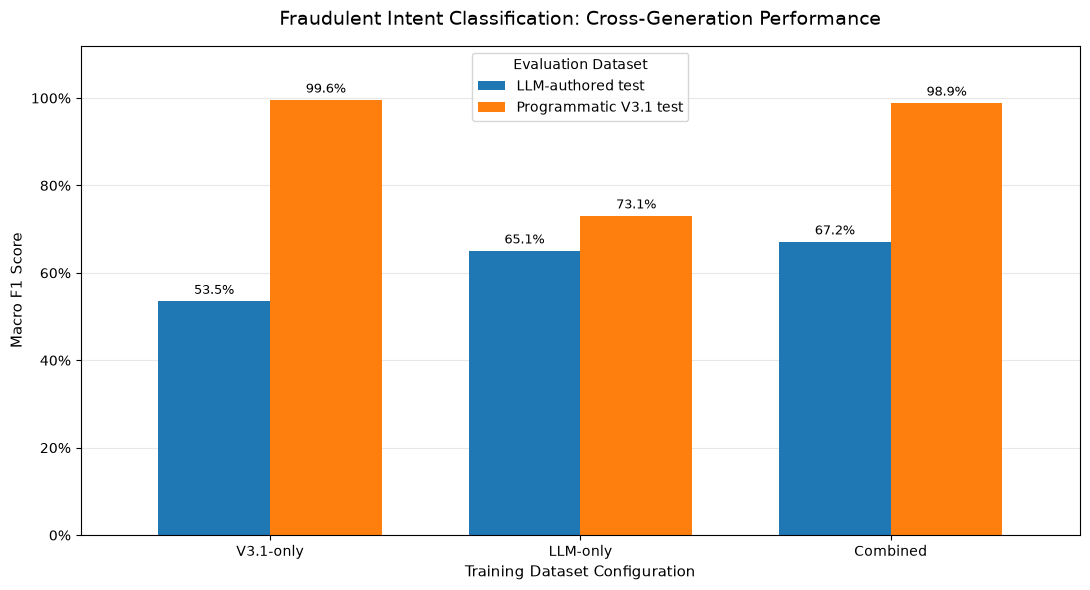

In [29]:
# Visualize fraudulent intent Macro F1 across all three training conditions

intent_plot_data = pd.concat([
    v31_only_intent_evaluation.assign(Training_Condition="V3.1-only"),
    llm_intent_evaluation.assign(Training_Condition="LLM-only"),
    combined_intent_evaluation.assign(Training_Condition="Combined")
], ignore_index=True)

intent_pivot = intent_plot_data.pivot(
    index="Training_Condition",
    columns="Test Dataset",
    values="Macro F1"
).reindex(["V3.1-only", "LLM-only", "Combined"])

ax = intent_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.72
)

ax.set_title(
    "Fraudulent Intent Classification: Cross-Generation Performance",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Training Dataset Configuration", fontsize=11)
ax.set_ylabel("Macro F1 Score", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(title="Evaluation Dataset")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        labels=[f"{bar.get_height() * 100:.1f}%" for bar in container],
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [30]:
# Train the scam subtype classifier using only V3.1 training data

v31_subtype_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

v31_subtype_model.fit(
    train_v31["normalized_text"],
    train_v31["scam_subtype"]
)

print("V3.1-only subtype model trained successfully.")
print(f"Training records: {len(train_v31):,}")
print(f"Subtype classes: {train_v31['scam_subtype'].nunique()}")
print(f"Vocabulary size: {len(v31_subtype_model.named_steps['tfidf'].vocabulary_):,}")

V3.1-only subtype model trained successfully.
Training records: 6,240
Subtype classes: 13
Vocabulary size: 13,252


In [31]:
# Evaluate the V3.1-only subtype model on both independent test sets

v31_subtype_test = df_v31[df_v31["split_partition"] == "test"].copy()

v31_only_llm_subtype_predictions = v31_subtype_model.predict(
    llm_test["normalized_text"]
)

v31_only_test_subtype_predictions = v31_subtype_model.predict(
    v31_subtype_test["normalized_text"]
)

v31_only_subtype_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["scam_subtype"], v31_only_llm_subtype_predictions),
    ("Programmatic V3.1 test", v31_subtype_test["scam_subtype"], v31_only_test_subtype_predictions)
]:
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    v31_only_subtype_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

v31_only_subtype_evaluation = pd.DataFrame(v31_only_subtype_results)

display(
    v31_only_subtype_evaluation.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

,Test Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LLM-authored test,273,0.4579,0.6388,0.4579,0.4819,0.4819
1,Programmatic V3.1 test,780,0.9962,0.9962,0.9962,0.9962,0.9962


In [32]:
# Combine both training datasets and train the scam subtype classifier

combined_subtype_train = pd.concat(
    [train_v31, llm_train],
    ignore_index=True
)

combined_subtype_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

combined_subtype_model.fit(
    combined_subtype_train["normalized_text"],
    combined_subtype_train["scam_subtype"]
)

print("Combined subtype model trained successfully.")
print(f"V3.1 training records: {len(train_v31):,}")
print(f"LLM training records: {len(llm_train):,}")
print(f"Combined training records: {len(combined_subtype_train):,}")
print(f"Subtype classes: {combined_subtype_train['scam_subtype'].nunique()}")
print(f"Vocabulary size: {len(combined_subtype_model.named_steps['tfidf'].vocabulary_):,}")

Combined subtype model trained successfully.
V3.1 training records: 6,240
LLM training records: 2,184
Combined training records: 8,424
Subtype classes: 13
Vocabulary size: 33,449


In [33]:
# Evaluate the combined subtype model on both independent test sets

combined_llm_subtype_predictions = combined_subtype_model.predict(
    llm_test["normalized_text"]
)

combined_v31_subtype_predictions = combined_subtype_model.predict(
    v31_subtype_test["normalized_text"]
)

combined_subtype_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["scam_subtype"], combined_llm_subtype_predictions),
    ("Programmatic V3.1 test", v31_subtype_test["scam_subtype"], combined_v31_subtype_predictions)
]:
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    combined_subtype_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

combined_subtype_evaluation = pd.DataFrame(combined_subtype_results)

display(
    combined_subtype_evaluation.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

,Test Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LLM-authored test,273,0.7179,0.7703,0.7179,0.7099,0.7099
1,Programmatic V3.1 test,780,0.9962,0.9963,0.9962,0.9962,0.9962


In [35]:
# Recreate the LLM-only subtype evaluation results for plotting

llm_only_llm_predictions = llm_subtype_model.predict(
    llm_test["normalized_text"]
)

llm_only_v31_predictions = llm_subtype_model.predict(
    v31_subtype_test["normalized_text"]
)

llm_subtype_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["scam_subtype"], llm_only_llm_predictions),
    ("Programmatic V3.1 test", v31_subtype_test["scam_subtype"], llm_only_v31_predictions)
]:
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    llm_subtype_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

llm_subtype_evaluation = pd.DataFrame(llm_subtype_results)

display(llm_subtype_evaluation)

,Test Dataset,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,LLM-authored test,273,0.732601,0.757505,0.732601,0.729230,0.729230
1,Programmatic V3.1 test,780,0.965385,0.967865,0.965385,0.965227,0.965227


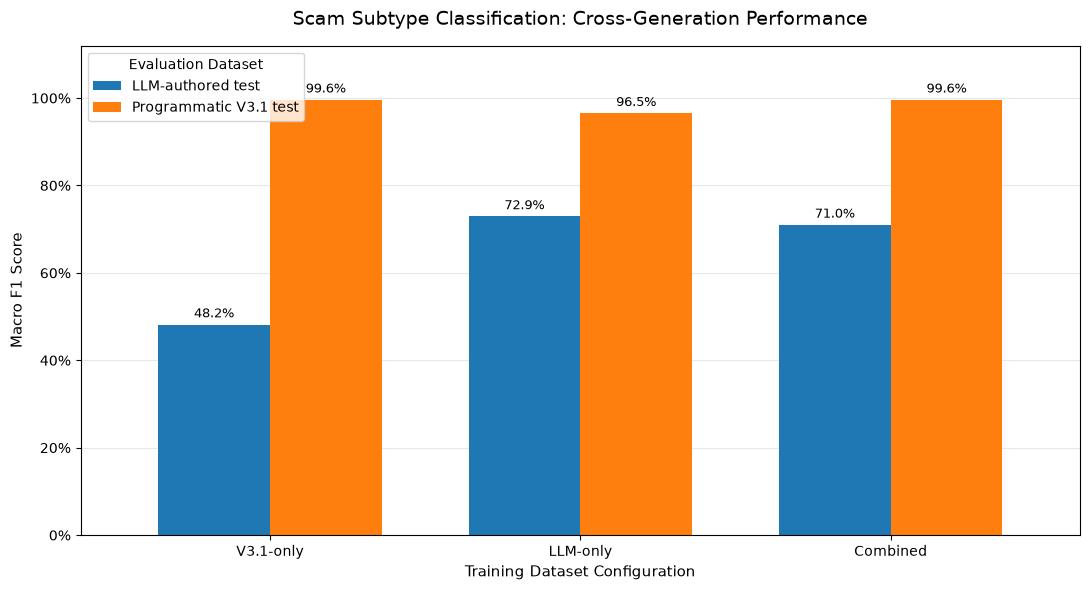

In [36]:
# Visualize scam subtype Macro F1 across all three training conditions

subtype_plot_data = pd.concat([
    v31_only_subtype_evaluation.assign(Training_Condition="V3.1-only"),
    llm_subtype_evaluation.assign(Training_Condition="LLM-only"),
    combined_subtype_evaluation.assign(Training_Condition="Combined")
], ignore_index=True)

subtype_pivot = subtype_plot_data.pivot(
    index="Training_Condition",
    columns="Test Dataset",
    values="Macro F1"
).reindex(["V3.1-only", "LLM-only", "Combined"])

ax = subtype_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.72
)

ax.set_title(
    "Scam Subtype Classification: Cross-Generation Performance",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Training Dataset Configuration", fontsize=11)
ax.set_ylabel("Macro F1 Score", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(title="Evaluation Dataset")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_height() * 100:.1f}%" for bar in container],
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [37]:
# Check annotated and unannotated records before social-engineering experiments

import json

def has_tactic_annotation(value):
    if pd.isna(value) or not str(value).strip():
        return False
    return len(json.loads(value)) > 0

tactic_partitions = {
    "V3.1 train": train_v31,
    "V3.1 test": v31_subtype_test,
    "LLM train": llm_train,
    "LLM test": llm_test
}

tactic_coverage = []

for partition_name, partition_df in tactic_partitions.items():
    annotated_mask = partition_df["social_engineering_tactics"].apply(
        has_tactic_annotation
    )

    tactic_coverage.append({
        "Partition": partition_name,
        "Total records": len(partition_df),
        "Annotated records": int(annotated_mask.sum()),
        "Unannotated records": int((~annotated_mask).sum()),
        "Annotation coverage": annotated_mask.mean()
    })

tactic_coverage_df = pd.DataFrame(tactic_coverage)

display(
    tactic_coverage_df.style.format({
        "Annotation coverage": "{:.2%}"
    })
)

,Partition,Total records,Annotated records,Unannotated records,Annotation coverage
0,V3.1 train,6240,5166,1074,82.79%
1,V3.1 test,780,639,141,81.92%
2,LLM train,2184,2184,0,100.00%
3,LLM test,273,273,0,100.00%


In [38]:
# Create annotation-filtered datasets for social-engineering classification

train_v31_tactics = train_v31[
    train_v31["social_engineering_tactics"].apply(has_tactic_annotation)
].copy()

v31_test_tactics = v31_subtype_test[
    v31_subtype_test["social_engineering_tactics"].apply(has_tactic_annotation)
].copy()

llm_train_tactics = llm_train.copy()
llm_test_tactics = llm_test.copy()

for dataset_name, dataset in [
    ("V3.1 training", train_v31_tactics),
    ("V3.1 test", v31_test_tactics),
    ("LLM training", llm_train_tactics),
    ("LLM test", llm_test_tactics)
]:
    dataset["tactics_list"] = dataset["social_engineering_tactics"].apply(json.loads)

    print(f"{dataset_name}: {len(dataset):,} annotated records")

print("\nAll tactic datasets prepared successfully.")

V3.1 training: 5,166 annotated records
V3.1 test: 639 annotated records
LLM training: 2,184 annotated records
LLM test: 273 annotated records

All tactic datasets prepared successfully.


In [39]:
# Encode social-engineering tactics into consistent multi-label targets

from sklearn.preprocessing import MultiLabelBinarizer

tactic_mlb = MultiLabelBinarizer()

Y_v31_tactics = tactic_mlb.fit_transform(
    train_v31_tactics["tactics_list"]
)

Y_llm_tactics = tactic_mlb.transform(
    llm_train_tactics["tactics_list"]
)

Y_v31_tactics_test = tactic_mlb.transform(
    v31_test_tactics["tactics_list"]
)

Y_llm_tactics_test = tactic_mlb.transform(
    llm_test_tactics["tactics_list"]
)

print(f"Number of tactic classes: {len(tactic_mlb.classes_)}")
print(f"Tactic classes: {list(tactic_mlb.classes_)}")
print(f"V3.1 training target shape: {Y_v31_tactics.shape}")
print(f"LLM training target shape: {Y_llm_tactics.shape}")
print(f"V3.1 test target shape: {Y_v31_tactics_test.shape}")
print(f"LLM test target shape: {Y_llm_tactics_test.shape}")

Number of tactic classes: 9
Tactic classes: ['authority_impersonation', 'emotional_manipulation', 'false_legitimacy', 'fear_or_threat', 'reward_or_benefit', 'scarcity', 'secrecy', 'trust_exploitation', 'urgency']
V3.1 training target shape: (5166, 9)
LLM training target shape: (2184, 9)
V3.1 test target shape: (639, 9)
LLM test target shape: (273, 9)


In [40]:
# Train the V3.1-only multi-label social-engineering classifier

v31_tactic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", OneVsRestClassifier(
        LogisticRegression(
            C=1,
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    ))
])

v31_tactic_model.fit(
    train_v31_tactics["normalized_text"],
    Y_v31_tactics
)

print("V3.1-only tactic model trained successfully.")
print(f"Training records: {len(train_v31_tactics):,}")
print(f"Tactic classes: {len(tactic_mlb.classes_)}")
print(f"Vocabulary size: {len(v31_tactic_model.named_steps['tfidf'].vocabulary_):,}")

V3.1-only tactic model trained successfully.
Training records: 5,166
Tactic classes: 9
Vocabulary size: 11,409


In [41]:
# Evaluate V3.1-only tactic classification on both test datasets

v31_tactic_prob_llm = v31_tactic_model.predict_proba(
    llm_test_tactics["normalized_text"]
)

v31_tactic_prob_test = v31_tactic_model.predict_proba(
    v31_test_tactics["normalized_text"]
)

v31_tactic_pred_llm = (v31_tactic_prob_llm >= 0.5).astype(int)
v31_tactic_pred_test = (v31_tactic_prob_test >= 0.5).astype(int)

tactic_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", Y_llm_tactics_test, v31_tactic_pred_llm),
    ("Programmatic V3.1 test", Y_v31_tactics_test, v31_tactic_pred_test)
]:
    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )

    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    tactic_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Micro Precision": micro_p,
        "Micro Recall": micro_r,
        "Micro F1": micro_f1,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Hamming Loss": np.mean(y_true != y_pred)
    })

v31_only_tactic_evaluation = pd.DataFrame(tactic_results)

display(
    v31_only_tactic_evaluation.style.format({
        col: "{:.4f}" for col in v31_only_tactic_evaluation.columns
        if col not in ["Test Dataset", "Samples"]
    })
)

,Test Dataset,Samples,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Hamming Loss
0,LLM-authored test,273,0.8355,0.1558,0.2627,0.8188,0.1254,0.2046,0.2902
1,Programmatic V3.1 test,639,0.9901,1.0000,0.9950,0.9884,1.0000,0.9941,0.0017


In [42]:
# Inspect per-class social-engineering performance on LLM-authored messages

tactic_class_report = pd.DataFrame(
    classification_report(
        Y_llm_tactics_test,
        v31_tactic_pred_llm,
        target_names=tactic_mlb.classes_,
        output_dict=True,
        zero_division=0
    )
).T

tactic_class_report = tactic_class_report.loc[
    list(tactic_mlb.classes_),
    ["precision", "recall", "f1-score", "support"]
]

display(
    tactic_class_report.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

,precision,recall,f1-score,support
authority_impersonation,0.8889,0.1053,0.1882,76
emotional_manipulation,0.0000,0.0000,0.0000,55
false_legitimacy,0.7333,0.1897,0.3014,174
fear_or_threat,0.9000,0.1034,0.1856,87
reward_or_benefit,1.0000,0.0085,0.0168,118
scarcity,1.0000,0.0732,0.1364,41
secrecy,1.0000,0.1667,0.2857,6
trust_exploitation,1.0000,0.1294,0.2292,85
urgency,0.8472,0.3526,0.4980,173


In [43]:
# Train the LLM-only multi-label social-engineering classifier

llm_tactic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", OneVsRestClassifier(
        LogisticRegression(
            C=1,
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    ))
])

llm_tactic_model.fit(
    llm_train_tactics["normalized_text"],
    Y_llm_tactics
)

print("LLM-only tactic model trained successfully.")
print(f"Training records: {len(llm_train_tactics):,}")
print(f"Tactic classes: {len(tactic_mlb.classes_)}")
print(f"Vocabulary size: {len(llm_tactic_model.named_steps['tfidf'].vocabulary_):,}")

LLM-only tactic model trained successfully.
Training records: 2,184
Tactic classes: 9
Vocabulary size: 23,646


In [44]:
# Evaluate LLM-only tactic classification on both test datasets

llm_tactic_prob_llm = llm_tactic_model.predict_proba(
    llm_test_tactics["normalized_text"]
)

llm_tactic_prob_v31 = llm_tactic_model.predict_proba(
    v31_test_tactics["normalized_text"]
)

llm_tactic_pred_llm = (llm_tactic_prob_llm >= 0.5).astype(int)
llm_tactic_pred_v31 = (llm_tactic_prob_v31 >= 0.5).astype(int)

llm_tactic_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", Y_llm_tactics_test, llm_tactic_pred_llm),
    ("Programmatic V3.1 test", Y_v31_tactics_test, llm_tactic_pred_v31)
]:
    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )

    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    llm_tactic_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Micro Precision": micro_p,
        "Micro Recall": micro_r,
        "Micro F1": micro_f1,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Hamming Loss": np.mean(y_true != y_pred)
    })

llm_only_tactic_evaluation = pd.DataFrame(llm_tactic_results)

display(
    llm_only_tactic_evaluation.style.format({
        col: "{:.4f}" for col in llm_only_tactic_evaluation.columns
        if col not in ["Test Dataset", "Samples"]
    })
)

,Test Dataset,Samples,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Hamming Loss
0,LLM-authored test,273,0.7829,0.7742,0.7785,0.6741,0.6729,0.6722,0.1461
1,Programmatic V3.1 test,639,0.4020,0.7900,0.5329,0.4747,0.7480,0.4834,0.2408


In [45]:
# Combine annotated training records and train the multi-label tactic classifier

combined_tactic_train = pd.concat(
    [train_v31_tactics, llm_train_tactics],
    ignore_index=True
)

Y_combined_tactics = np.vstack([
    Y_v31_tactics,
    Y_llm_tactics
])

combined_tactic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", OneVsRestClassifier(
        LogisticRegression(
            C=1,
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    ))
])

combined_tactic_model.fit(
    combined_tactic_train["normalized_text"],
    Y_combined_tactics
)

print("Combined tactic model trained successfully.")
print(f"V3.1 annotated records: {len(train_v31_tactics):,}")
print(f"LLM annotated records: {len(llm_train_tactics):,}")
print(f"Combined training records: {len(combined_tactic_train):,}")
print(f"Tactic classes: {len(tactic_mlb.classes_)}")
print(f"Vocabulary size: {len(combined_tactic_model.named_steps['tfidf'].vocabulary_):,}")

Combined tactic model trained successfully.
V3.1 annotated records: 5,166
LLM annotated records: 2,184
Combined training records: 7,350
Tactic classes: 9
Vocabulary size: 31,826


In [46]:
# Evaluate combined tactic classification on both independent test datasets

combined_tactic_prob_llm = combined_tactic_model.predict_proba(
    llm_test_tactics["normalized_text"]
)

combined_tactic_prob_v31 = combined_tactic_model.predict_proba(
    v31_test_tactics["normalized_text"]
)

combined_tactic_pred_llm = (combined_tactic_prob_llm >= 0.5).astype(int)
combined_tactic_pred_v31 = (combined_tactic_prob_v31 >= 0.5).astype(int)

combined_tactic_results = []

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", Y_llm_tactics_test, combined_tactic_pred_llm),
    ("Programmatic V3.1 test", Y_v31_tactics_test, combined_tactic_pred_v31)
]:
    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )

    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    combined_tactic_results.append({
        "Test Dataset": dataset_name,
        "Samples": len(y_true),
        "Micro Precision": micro_p,
        "Micro Recall": micro_r,
        "Micro F1": micro_f1,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Hamming Loss": np.mean(y_true != y_pred)
    })

combined_tactic_evaluation = pd.DataFrame(combined_tactic_results)

display(
    combined_tactic_evaluation.style.format({
        col: "{:.4f}" for col in combined_tactic_evaluation.columns
        if col not in ["Test Dataset", "Samples"]
    })
)

,Test Dataset,Samples,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Hamming Loss
0,LLM-authored test,273,0.7246,0.8650,0.7886,0.6238,0.7293,0.6667,0.1538
1,Programmatic V3.1 test,639,0.9615,0.9990,0.9799,0.9531,0.9994,0.9746,0.0071


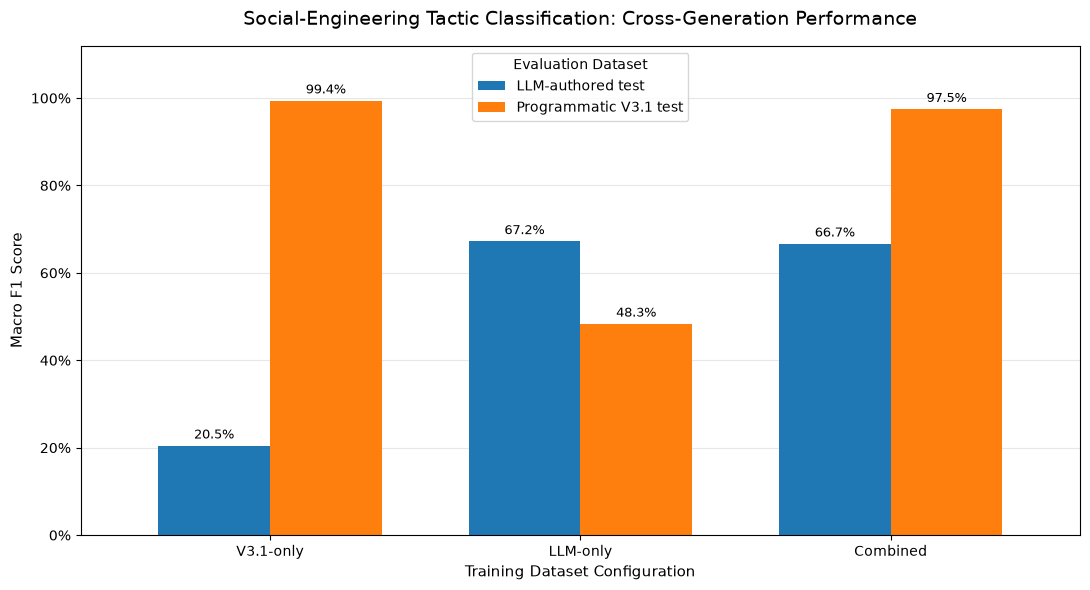

In [47]:
# Visualize social-engineering tactic Macro F1 across all three training conditions

tactic_plot_data = pd.concat([
    v31_only_tactic_evaluation.assign(Training_Condition="V3.1-only"),
    llm_only_tactic_evaluation.assign(Training_Condition="LLM-only"),
    combined_tactic_evaluation.assign(Training_Condition="Combined")
], ignore_index=True)

tactic_pivot = tactic_plot_data.pivot(
    index="Training_Condition",
    columns="Test Dataset",
    values="Macro F1"
).reindex(["V3.1-only", "LLM-only", "Combined"])

ax = tactic_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.72
)

ax.set_title(
    "Social-Engineering Tactic Classification: Cross-Generation Performance",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Training Dataset Configuration", fontsize=11)
ax.set_ylabel("Macro F1 Score", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(title="Evaluation Dataset")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_height() * 100:.1f}%" for bar in container],
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

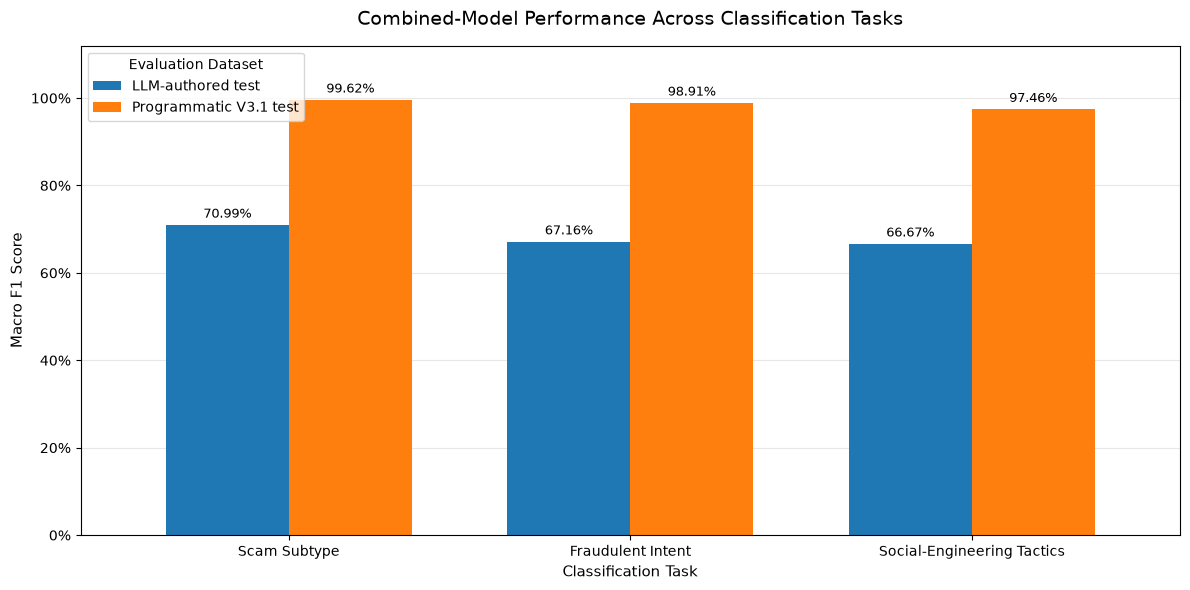

In [48]:
# Compare combined-model Macro F1 across all three classification tasks

combined_performance = pd.DataFrame({
    "Classification Task": [
        "Scam Subtype",
        "Fraudulent Intent",
        "Social-Engineering Tactics"
    ],
    "LLM-authored test": [
        combined_subtype_evaluation.loc[0, "Macro F1"],
        combined_intent_evaluation.loc[0, "Macro F1"],
        combined_tactic_evaluation.loc[0, "Macro F1"]
    ],
    "Programmatic V3.1 test": [
        combined_subtype_evaluation.loc[1, "Macro F1"],
        combined_intent_evaluation.loc[1, "Macro F1"],
        combined_tactic_evaluation.loc[1, "Macro F1"]
    ]
}).set_index("Classification Task")

ax = combined_performance.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.72
)

ax.set_title(
    "Combined-Model Performance Across Classification Tasks",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Classification Task", fontsize=11)
ax.set_ylabel("Macro F1 Score", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)
ax.legend(title="Evaluation Dataset")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{bar.get_height() * 100:.2f}%"
            for bar in container
        ],
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [49]:
# Consolidate all experimental results into one master comparison table

evaluation_groups = [
    ("Scam Subtype", "V3.1-only", v31_only_subtype_evaluation),
    ("Scam Subtype", "LLM-only", llm_subtype_evaluation),
    ("Scam Subtype", "Combined", combined_subtype_evaluation),

    ("Fraudulent Intent", "V3.1-only", v31_only_intent_evaluation),
    ("Fraudulent Intent", "LLM-only", llm_intent_evaluation),
    ("Fraudulent Intent", "Combined", combined_intent_evaluation),

    ("Social-Engineering Tactics", "V3.1-only", v31_only_tactic_evaluation),
    ("Social-Engineering Tactics", "LLM-only", llm_only_tactic_evaluation),
    ("Social-Engineering Tactics", "Combined", combined_tactic_evaluation)
]

master_results = []

for task_name, condition, evaluation_df in evaluation_groups:
    for _, result in evaluation_df.iterrows():
        master_results.append({
            "Classification Task": task_name,
            "Training Condition": condition,
            "Test Dataset": result["Test Dataset"],
            "Samples": result["Samples"],
            "Accuracy": result.get("Accuracy", np.nan),
            "Macro F1": result["Macro F1"],
            "Weighted F1": result.get("Weighted F1", np.nan),
            "Micro F1": result.get("Micro F1", np.nan),
            "Hamming Loss": result.get("Hamming Loss", np.nan)
        })

master_results_df = pd.DataFrame(master_results)

display(
    master_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Micro F1": "{:.4f}",
        "Hamming Loss": "{:.4f}"
    }, na_rep="—")
)

,Classification Task,Training Condition,Test Dataset,Samples,Accuracy,Macro F1,Weighted F1,Micro F1,Hamming Loss
0,Scam Subtype,V3.1-only,LLM-authored test,273,0.4579,0.4819,0.4819,—,—
1,Scam Subtype,V3.1-only,Programmatic V3.1 test,780,0.9962,0.9962,0.9962,—,—
2,Scam Subtype,LLM-only,LLM-authored test,273,0.7326,0.7292,0.7292,—,—
3,Scam Subtype,LLM-only,Programmatic V3.1 test,780,0.9654,0.9652,0.9652,—,—
4,Scam Subtype,Combined,LLM-authored test,273,0.7179,0.7099,0.7099,—,—
5,Scam Subtype,Combined,Programmatic V3.1 test,780,0.9962,0.9962,0.9962,—,—
6,Fraudulent Intent,V3.1-only,LLM-authored test,273,0.6337,0.5354,0.6251,—,—
7,Fraudulent Intent,V3.1-only,Programmatic V3.1 test,780,0.9974,0.9960,0.9974,—,—
8,Fraudulent Intent,LLM-only,LLM-authored test,273,0.7033,0.6509,0.7123,—,—
9,Fraudulent Intent,LLM-only,Programmatic V3.1 test,780,0.8372,0.7310,0.8205,—,—


In [50]:
# Quantify Macro F1 differences between the two evaluation distributions

macro_f1_comparison = master_results_df.pivot_table(
    index=["Classification Task", "Training Condition"],
    columns="Test Dataset",
    values="Macro F1"
).reset_index()

macro_f1_comparison["V3.1 minus LLM (pp)"] = (
    macro_f1_comparison["Programmatic V3.1 test"]
    - macro_f1_comparison["LLM-authored test"]
) * 100

macro_f1_comparison["Absolute Performance Gap (pp)"] = (
    macro_f1_comparison["V3.1 minus LLM (pp)"].abs()
)

display(
    macro_f1_comparison.style.format({
        "LLM-authored test": "{:.4f}",
        "Programmatic V3.1 test": "{:.4f}",
        "V3.1 minus LLM (pp)": "{:+.2f}",
        "Absolute Performance Gap (pp)": "{:.2f}"
    })
)

Test Dataset,Classification Task,Training Condition,LLM-authored test,Programmatic V3.1 test,V3.1 minus LLM (pp),Absolute Performance Gap (pp)
0,Fraudulent Intent,Combined,0.6716,0.9891,+31.75,31.75
1,Fraudulent Intent,LLM-only,0.6509,0.7310,+8.01,8.01
2,Fraudulent Intent,V3.1-only,0.5354,0.9960,+46.07,46.07
3,Scam Subtype,Combined,0.7099,0.9962,+28.62,28.62
4,Scam Subtype,LLM-only,0.7292,0.9652,+23.60,23.60
5,Scam Subtype,V3.1-only,0.4819,0.9962,+51.43,51.43
6,Social-Engineering Tactics,Combined,0.6667,0.9746,+30.79,30.79
7,Social-Engineering Tactics,LLM-only,0.6722,0.4834,-18.88,18.88
8,Social-Engineering Tactics,V3.1-only,0.2046,0.9941,+78.95,78.95


In [51]:
# Analyze per-class performance of the combined subtype model

combined_subtype_reports = {}

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["scam_subtype"], combined_llm_subtype_predictions),
    ("Programmatic V3.1 test", v31_subtype_test["scam_subtype"], combined_v31_subtype_predictions)
]:
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    class_report = pd.DataFrame(report).T

    combined_subtype_reports[dataset_name] = class_report.iloc[:-3][
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score")

    print(f"\n{dataset_name}")
    display(
        combined_subtype_reports[dataset_name].style.format({
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:.0f}"
        })
    )


LLM-authored test


,precision,recall,f1-score,support
tax_payment,0.2800,0.3333,0.3043,21
recovery_support,1.0000,0.2381,0.3846,21
family_emergency_request,1.0000,0.3810,0.5517,21
romance_financial_manipulation,0.5000,0.7143,0.5882,21
account_verification,0.5357,0.7143,0.6122,21
refund_chargeback,0.6250,0.7143,0.6667,21
loan_offer,0.6818,0.7143,0.6977,21
invoice_payment_request,0.7143,0.9524,0.8163,21
job_task_commission,0.9444,0.8095,0.8718,21
investment_crypto,0.9444,0.8095,0.8718,21



Programmatic V3.1 test


,precision,recall,f1-score,support
refund_chargeback,1.0000,0.9667,0.9831,60
invoice_payment_request,0.9677,1.0000,0.9836,60
card_transaction_alert,1.0000,0.9833,0.9916,60
account_verification,0.9836,1.0000,0.9917,60
family_emergency_request,1.0000,1.0000,1.0000,60
investment_crypto,1.0000,1.0000,1.0000,60
job_task_commission,1.0000,1.0000,1.0000,60
charity_donation,1.0000,1.0000,1.0000,60
loan_offer,1.0000,1.0000,1.0000,60
prize_reward,1.0000,1.0000,1.0000,60


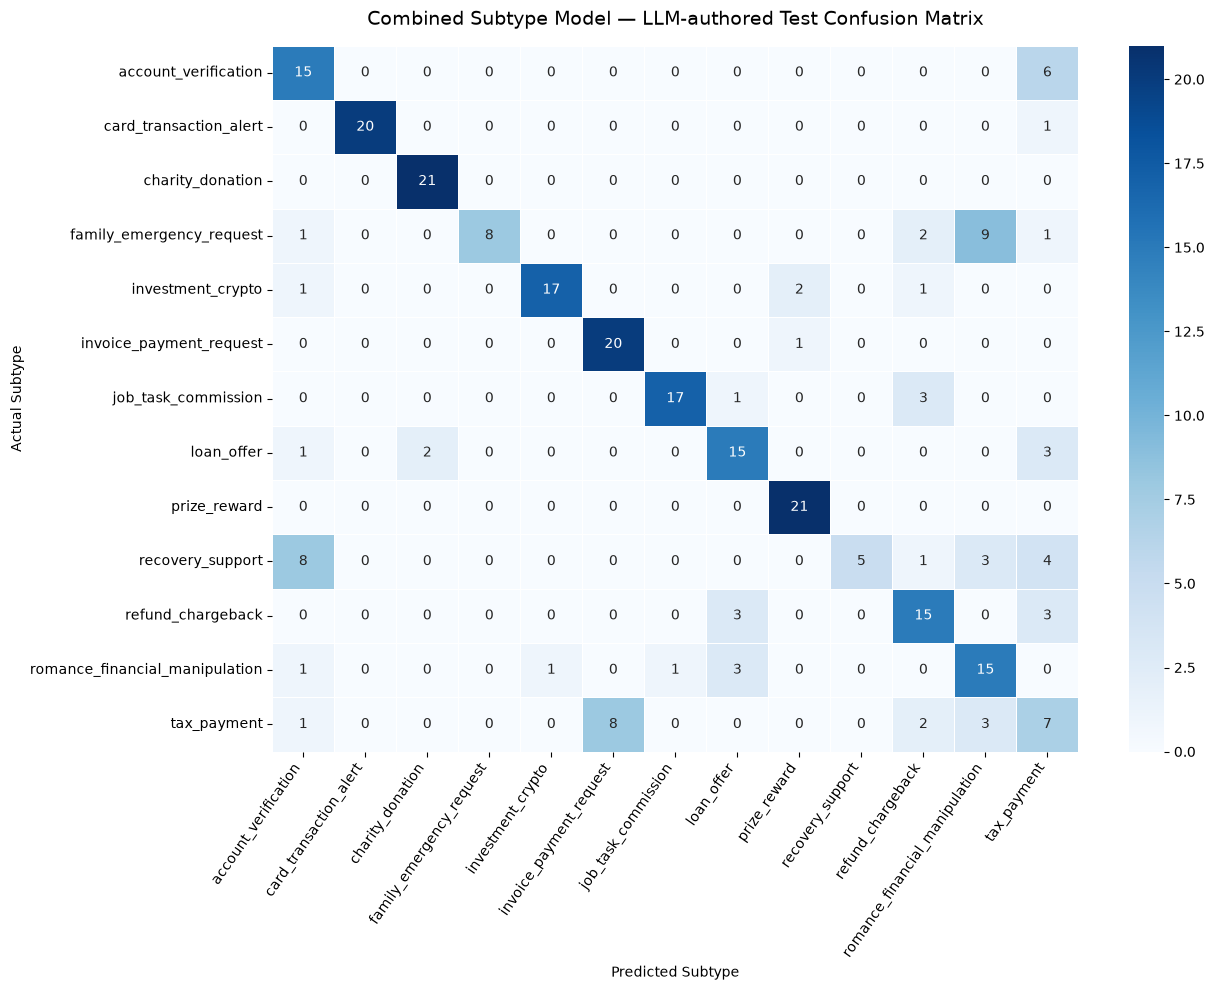

In [52]:
# Visualize subtype misclassifications on the LLM-authored test set

subtype_labels = sorted(train_v31["scam_subtype"].unique())

subtype_cm = confusion_matrix(
    llm_test["scam_subtype"],
    combined_llm_subtype_predictions,
    labels=subtype_labels
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    subtype_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=subtype_labels,
    yticklabels=subtype_labels,
    linewidths=0.5
)

plt.title(
    "Combined Subtype Model — LLM-authored Test Confusion Matrix",
    fontsize=14,
    pad=15
)
plt.xlabel("Predicted Subtype")
plt.ylabel("Actual Subtype")
plt.xticks(rotation=55, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [53]:
# Analyze per-class performance of the combined fraudulent intent model

combined_intent_reports = {}

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", llm_test["fraudulent_intent"], combined_llm_intent_predictions),
    ("Programmatic V3.1 test", v31_intent_test["fraudulent_intent"], combined_v31_intent_predictions)
]:
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    class_report = pd.DataFrame(report).T

    combined_intent_reports[dataset_name] = class_report.iloc[:-3][
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score")

    print(f"\n{dataset_name}")
    display(
        combined_intent_reports[dataset_name].style.format({
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:.0f}"
        })
    )


LLM-authored test


,precision,recall,f1-score,support
gain_account_or_device_access,0.3438,0.6471,0.4490,17
obtain_personal_or_financial_information,0.7917,0.6032,0.6847,63
obtain_credentials_or_codes,0.6724,0.7222,0.6964,54
induce_fraudulent_investment,0.7895,0.7143,0.7500,21
induce_payment_or_transfer,0.7845,0.7712,0.7778,118



Programmatic V3.1 test


,precision,recall,f1-score,support
induce_fraudulent_investment,0.9483,1.0000,0.9735,55
gain_account_or_device_access,1.0000,0.9667,0.9831,60
obtain_credentials_or_codes,1.0000,0.9844,0.9921,128
obtain_personal_or_financial_information,0.9940,1.0000,0.9970,165
induce_payment_or_transfer,1.0000,1.0000,1.0000,372


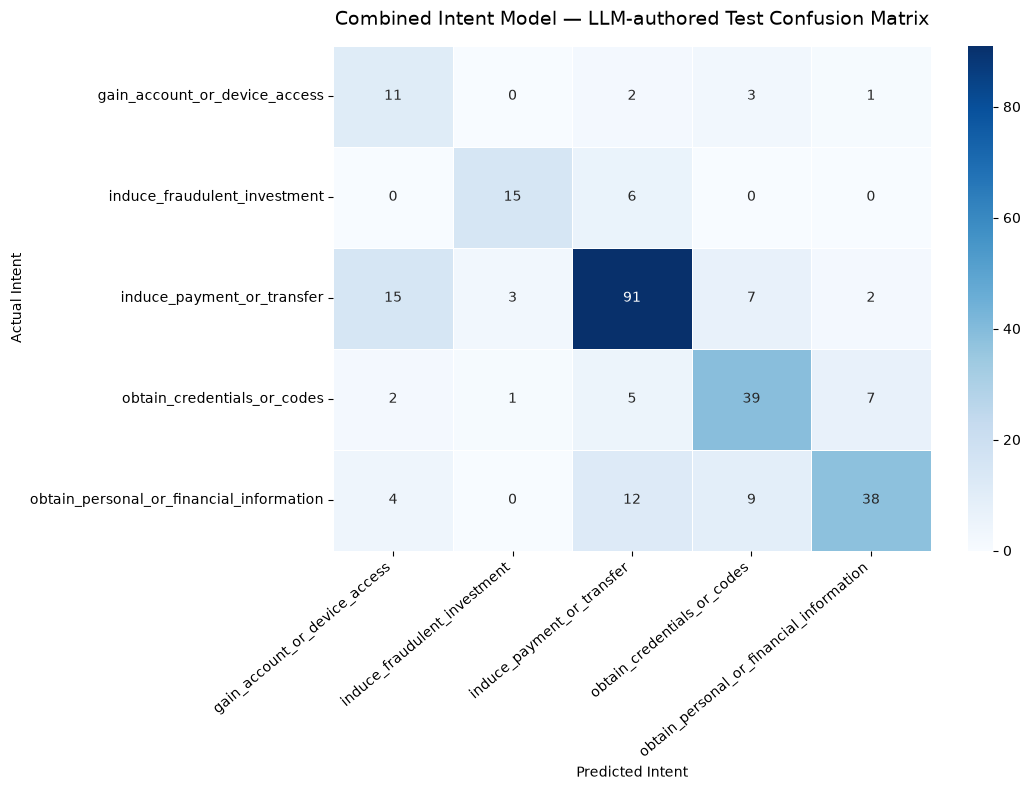

In [54]:
# Visualize fraudulent intent misclassifications on the LLM-authored test set

intent_labels = sorted(train_v31["fraudulent_intent"].unique())

intent_cm = confusion_matrix(
    llm_test["fraudulent_intent"],
    combined_llm_intent_predictions,
    labels=intent_labels
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    intent_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_labels,
    yticklabels=intent_labels,
    linewidths=0.5
)

plt.title(
    "Combined Intent Model — LLM-authored Test Confusion Matrix",
    fontsize=14,
    pad=15
)
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
# Analyze per-class performance of the combined tactic model

combined_tactic_reports = {}

for dataset_name, y_true, y_pred in [
    ("LLM-authored test", Y_llm_tactics_test, combined_tactic_pred_llm),
    ("Programmatic V3.1 test", Y_v31_tactics_test, combined_tactic_pred_v31)
]:
    report = classification_report(
        y_true,
        y_pred,
        target_names=tactic_mlb.classes_,
        output_dict=True,
        zero_division=0
    )

    class_report = pd.DataFrame(report).T

    combined_tactic_reports[dataset_name] = class_report.loc[
        list(tactic_mlb.classes_),
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score")

    print(f"\n{dataset_name}")
    display(
        combined_tactic_reports[dataset_name].style.format({
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:.0f}"
        })
    )


LLM-authored test


,precision,recall,f1-score,support
secrecy,0.0000,0.0000,0.0000,6
scarcity,0.5185,0.3415,0.4118,41
authority_impersonation,0.5766,0.8421,0.6845,76
fear_or_threat,0.6525,0.8851,0.7512,87
trust_exploitation,0.7742,0.8471,0.8090,85
reward_or_benefit,0.7500,0.8898,0.8140,118
false_legitimacy,0.7225,0.9425,0.8180,174
emotional_manipulation,0.8033,0.8909,0.8448,55
urgency,0.8163,0.9249,0.8672,173



Programmatic V3.1 test


,precision,recall,f1-score,support
emotional_manipulation,0.8182,1.0000,0.9000,72
trust_exploitation,0.8710,1.0000,0.9310,81
reward_or_benefit,0.9440,1.0000,0.9712,118
scarcity,0.9506,1.0000,0.9747,77
false_legitimacy,0.9945,0.9945,0.9945,183
authority_impersonation,1.0000,1.0000,1.0000,110
fear_or_threat,1.0000,1.0000,1.0000,63
secrecy,1.0000,1.0000,1.0000,82
urgency,1.0000,1.0000,1.0000,214


In [56]:
# Compare false positives and false negatives for each tactic on the LLM test set

from sklearn.metrics import multilabel_confusion_matrix

tactic_confusions = multilabel_confusion_matrix(
    Y_llm_tactics_test,
    combined_tactic_pred_llm
)

tactic_error_counts = pd.DataFrame([
    {
        "Tactic": tactic,
        "True Positives": matrix[1, 1],
        "False Positives": matrix[0, 1],
        "False Negatives": matrix[1, 0],
        "True Negatives": matrix[0, 0]
    }
    for tactic, matrix in zip(tactic_mlb.classes_, tactic_confusions)
])

display(
    tactic_error_counts.sort_values(
        "False Negatives",
        ascending=False
    ).reset_index(drop=True)
)

,Tactic,True Positives,False Positives,False Negatives,True Negatives
0,scarcity,14,13,27,219
1,trust_exploitation,72,21,13,167
2,reward_or_benefit,105,35,13,120
3,urgency,160,36,13,64
4,authority_impersonation,64,47,12,150
5,false_legitimacy,164,63,10,36
6,fear_or_threat,77,41,10,145
7,emotional_manipulation,49,12,6,206
8,secrecy,0,0,6,267


In [57]:
# Inspect class distributions before creating size-controlled training subsets

print("SCAM SUBTYPE DISTRIBUTION")
print("\nV3.1:")
display(train_v31["scam_subtype"].value_counts().sort_index())

print("\nLLM-authored:")
display(llm_train["scam_subtype"].value_counts().sort_index())

print("\nFRAUDULENT INTENT DISTRIBUTION")
print("\nV3.1:")
display(train_v31["fraudulent_intent"].value_counts().sort_index())

print("\nLLM-authored:")
display(llm_train["fraudulent_intent"].value_counts().sort_index())

print("\nTACTIC LABEL FREQUENCIES")
print("\nV3.1:")
display(pd.Series(
    Y_v31_tactics.sum(axis=0),
    index=tactic_mlb.classes_,
    name="Positive annotations"
))

print("\nLLM-authored:")
display(pd.Series(
    Y_llm_tactics.sum(axis=0),
    index=tactic_mlb.classes_,
    name="Positive annotations"
))

SCAM SUBTYPE DISTRIBUTION

V3.1:


scam_subtype
account_verification              480
card_transaction_alert            480
charity_donation                  480
family_emergency_request          480
investment_crypto                 480
invoice_payment_request           480
job_task_commission               480
loan_offer                        480
prize_reward                      480
recovery_support                  480
refund_chargeback                 480
romance_financial_manipulation    480
tax_payment                       480
Name: count, dtype: int64


LLM-authored:


scam_subtype
account_verification              168
card_transaction_alert            168
charity_donation                  168
family_emergency_request          168
investment_crypto                 168
invoice_payment_request           168
job_task_commission               168
loan_offer                        168
prize_reward                      168
recovery_support                  168
refund_chargeback                 168
romance_financial_manipulation    168
tax_payment                       168
Name: count, dtype: int64


FRAUDULENT INTENT DISTRIBUTION

V3.1:


fraudulent_intent
gain_account_or_device_access                478
induce_fraudulent_investment                 463
induce_payment_or_transfer                  2924
obtain_credentials_or_codes                  906
obtain_personal_or_financial_information    1469
Name: count, dtype: int64

... (2 outputs left out)


TACTIC LABEL FREQUENCIES

V3.1:


authority_impersonation     825
emotional_manipulation      577
false_legitimacy           1517
fear_or_threat              496
reward_or_benefit           893
scarcity                    576
secrecy                     695
trust_exploitation          743
urgency                    1922
Name: Positive annotations, dtype: int64


LLM-authored:


authority_impersonation     791
emotional_manipulation      441
false_legitimacy           1494
fear_or_threat              722
reward_or_benefit           817
scarcity                    228
secrecy                      32
trust_exploitation          632
urgency                    1389
Name: Positive annotations, dtype: int64

In [58]:
# Create reproducible, size-controlled combined training subsets

from sklearn.model_selection import train_test_split

def stratified_sample(df, label_column, sample_size, random_state):
    sampled, _ = train_test_split(
        df,
        train_size=sample_size,
        stratify=df[label_column],
        random_state=random_state
    )
    return sampled.copy()


# Subtype: preserve the 13-class distribution
v31_subtype_control = stratified_sample(
    train_v31, "scam_subtype", 4624, RANDOM_STATE
)
llm_subtype_control = stratified_sample(
    llm_train, "scam_subtype", 1616, RANDOM_STATE
)

combined_subtype_control = pd.concat(
    [v31_subtype_control, llm_subtype_control],
    ignore_index=True
)


# Intent: preserve each source's original intent distribution
v31_intent_control = stratified_sample(
    train_v31, "fraudulent_intent", 4624, RANDOM_STATE
)
llm_intent_control = stratified_sample(
    llm_train, "fraudulent_intent", 1616, RANDOM_STATE
)

combined_intent_control = pd.concat(
    [v31_intent_control, llm_intent_control],
    ignore_index=True
)


# Tactics: reproducible random sampling of annotated records
v31_tactic_control = train_v31_tactics.sample(
    n=3631, random_state=RANDOM_STATE
).copy()

llm_tactic_control = llm_train_tactics.sample(
    n=1535, random_state=RANDOM_STATE
).copy()

combined_tactic_control = pd.concat(
    [v31_tactic_control, llm_tactic_control],
    ignore_index=True
)

Y_tactic_control = tactic_mlb.transform(
    combined_tactic_control["tactics_list"]
)


# Verify sample sizes
control_sample_summary = pd.DataFrame([
    {
        "Task": "Scam Subtype",
        "V3.1": len(v31_subtype_control),
        "LLM-authored": len(llm_subtype_control),
        "Combined": len(combined_subtype_control)
    },
    {
        "Task": "Fraudulent Intent",
        "V3.1": len(v31_intent_control),
        "LLM-authored": len(llm_intent_control),
        "Combined": len(combined_intent_control)
    },
    {
        "Task": "Social-Engineering Tactics",
        "V3.1": len(v31_tactic_control),
        "LLM-authored": len(llm_tactic_control),
        "Combined": len(combined_tactic_control)
    }
])

display(control_sample_summary)

print("\nTactic control target shape:", Y_tactic_control.shape)

,Task,V3.1,LLM-authored,Combined
0,Scam Subtype,4624,1616,6240
1,Fraudulent Intent,4624,1616,6240
2,Social-Engineering Tactics,3631,1535,5166



Tactic control target shape: (5166, 9)


In [59]:
# Train the size-controlled combined subtype model

from sklearn.base import clone

controlled_combined_subtype_model = clone(v31_subtype_model)

controlled_combined_subtype_model.fit(
    combined_subtype_control["normalized_text"],
    combined_subtype_control["scam_subtype"]
)

print("Controlled combined subtype model trained successfully.")
print(f"Training samples: {len(combined_subtype_control):,}")
print(f"V3.1 contribution: {len(v31_subtype_control):,}")
print(f"LLM-authored contribution: {len(llm_subtype_control):,}")

Controlled combined subtype model trained successfully.
Training samples: 6,240
V3.1 contribution: 4,624
LLM-authored contribution: 1,616


In [60]:
# Evaluate the size-controlled subtype model on both test distributions

controlled_subtype_llm_predictions = controlled_combined_subtype_model.predict(
    llm_test["normalized_text"]
)

controlled_subtype_v31_predictions = controlled_combined_subtype_model.predict(
    v31_subtype_test["normalized_text"]
)

controlled_subtype_evaluation = pd.DataFrame([
    {
        "training_condition": "Size-controlled combined",
        "test_dataset": "LLM-authored",
        "samples": len(llm_test),
        "accuracy": accuracy_score(
            llm_test["scam_subtype"],
            controlled_subtype_llm_predictions
        ),
        "macro_f1": f1_score(
            llm_test["scam_subtype"],
            controlled_subtype_llm_predictions,
            average="macro"
        ),
        "weighted_f1": f1_score(
            llm_test["scam_subtype"],
            controlled_subtype_llm_predictions,
            average="weighted"
        )
    },
    {
        "training_condition": "Size-controlled combined",
        "test_dataset": "V3.1",
        "samples": len(v31_subtype_test),
        "accuracy": accuracy_score(
            v31_subtype_test["scam_subtype"],
            controlled_subtype_v31_predictions
        ),
        "macro_f1": f1_score(
            v31_subtype_test["scam_subtype"],
            controlled_subtype_v31_predictions,
            average="macro"
        ),
        "weighted_f1": f1_score(
            v31_subtype_test["scam_subtype"],
            controlled_subtype_v31_predictions,
            average="weighted"
        )
    }
])

display(controlled_subtype_evaluation.round(4))

,training_condition,test_dataset,samples,accuracy,macro_f1,weighted_f1
0,Size-controlled combined,LLM-authored,273,0.7106,0.7060,0.7060
1,Size-controlled combined,V3.1,780,0.9962,0.9962,0.9962


In [63]:
# Train the size-controlled combined fraudulent intent model

from sklearn.base import clone

controlled_combined_intent_model = clone(intent_model)

controlled_combined_intent_model.fit(
    combined_intent_control["normalized_text"],
    combined_intent_control["fraudulent_intent"]
)

print("Controlled combined intent model trained successfully.")
print(f"Training samples: {len(combined_intent_control):,}")
print(f"V3.1 contribution: {len(v31_intent_control):,}")
print(f"LLM-authored contribution: {len(llm_intent_control):,}")

Controlled combined intent model trained successfully.
Training samples: 6,240
V3.1 contribution: 4,624
LLM-authored contribution: 1,616


In [64]:
# Evaluate the size-controlled intent model on both test distributions

controlled_intent_llm_predictions = controlled_combined_intent_model.predict(
    llm_test["normalized_text"]
)

controlled_intent_v31_predictions = controlled_combined_intent_model.predict(
    v31_intent_test["normalized_text"]
)

controlled_intent_evaluation = pd.DataFrame([
    {
        "training_condition": "Size-controlled combined",
        "test_dataset": "LLM-authored",
        "samples": len(llm_test),
        "accuracy": accuracy_score(
            llm_test["fraudulent_intent"],
            controlled_intent_llm_predictions
        ),
        "macro_f1": f1_score(
            llm_test["fraudulent_intent"],
            controlled_intent_llm_predictions,
            average="macro"
        ),
        "weighted_f1": f1_score(
            llm_test["fraudulent_intent"],
            controlled_intent_llm_predictions,
            average="weighted"
        )
    },
    {
        "training_condition": "Size-controlled combined",
        "test_dataset": "V3.1",
        "samples": len(v31_intent_test),
        "accuracy": accuracy_score(
            v31_intent_test["fraudulent_intent"],
            controlled_intent_v31_predictions
        ),
        "macro_f1": f1_score(
            v31_intent_test["fraudulent_intent"],
            controlled_intent_v31_predictions,
            average="macro"
        ),
        "weighted_f1": f1_score(
            v31_intent_test["fraudulent_intent"],
            controlled_intent_v31_predictions,
            average="weighted"
        )
    }
])

display(controlled_intent_evaluation.round(4))

,training_condition,test_dataset,samples,accuracy,macro_f1,weighted_f1
0,Size-controlled combined,LLM-authored,273,0.7033,0.6559,0.7105
1,Size-controlled combined,V3.1,780,0.9949,0.9900,0.9949


In [65]:
# Train the size-controlled combined social-engineering tactic model

from sklearn.base import clone

controlled_combined_tactic_model = clone(v31_tactic_model)

controlled_combined_tactic_model.fit(
    combined_tactic_control["normalized_text"],
    Y_tactic_control
)

print("Controlled combined tactic model trained successfully.")
print(f"Training samples: {len(combined_tactic_control):,}")
print(f"V3.1 contribution: {len(v31_tactic_control):,}")
print(f"LLM-authored contribution: {len(llm_tactic_control):,}")
print(f"Number of tactic classes: {Y_tactic_control.shape[1]}")

Controlled combined tactic model trained successfully.
Training samples: 5,166
V3.1 contribution: 3,631
LLM-authored contribution: 1,535
Number of tactic classes: 9


In [66]:
# Evaluate the size-controlled tactic model on both annotated test distributions

controlled_tactic_llm_probabilities = controlled_combined_tactic_model.predict_proba(
    llm_test_tactics["normalized_text"]
)

controlled_tactic_v31_probabilities = controlled_combined_tactic_model.predict_proba(
    v31_test_tactics["normalized_text"]
)

controlled_tactic_llm_predictions = (
    controlled_tactic_llm_probabilities >= 0.5
).astype(int)

controlled_tactic_v31_predictions = (
    controlled_tactic_v31_probabilities >= 0.5
).astype(int)

def evaluate_multilabel_predictions(y_true, y_pred, dataset_name):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    micro_precision, micro_recall, micro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="micro",
        zero_division=0
    )

    return {
        "training_condition": "Size-controlled combined",
        "test_dataset": dataset_name,
        "samples": len(y_true),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "micro_precision": micro_precision,
        "micro_recall": micro_recall,
        "micro_f1": micro_f1,
        "hamming_loss": np.mean(y_true != y_pred)
    }

controlled_tactic_evaluation = pd.DataFrame([
    evaluate_multilabel_predictions(
        Y_llm_tactics_test,
        controlled_tactic_llm_predictions,
        "LLM-authored"
    ),
    evaluate_multilabel_predictions(
        Y_v31_tactics_test,
        controlled_tactic_v31_predictions,
        "V3.1"
    )
])

display(controlled_tactic_evaluation.round(4))

,training_condition,test_dataset,samples,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,hamming_loss
0,Size-controlled combined,LLM-authored,273,0.6184,0.7206,0.6576,0.7197,0.8601,0.7837,0.1575
1,Size-controlled combined,V3.1,639,0.9217,0.9988,0.9568,0.9336,0.9980,0.9647,0.0127



## Limitations and Key Observations

### Experimental Limitations

The experiments in this notebook have several limitations that must be considered when interpreting the results.

1. **Synthetic data dependency:** Both V3.1 and the LLM-authored dataset are synthetic. Performance on these datasets does not establish effectiveness on real-world financial scam communications.

2. **Generation-specific characteristics:** The two datasets were produced through different generation processes. Differences in vocabulary, writing style, scenario construction, and label distributions may influence model performance.

3. **Distribution imbalance:** The datasets do not have identical class distributions. Some fraudulent intent and social-engineering tactic categories are less represented than others, potentially affecting classification performance.

4. **Annotation limitations:** V3.1 contains records without social-engineering tactic annotations. These records were excluded from tactic classification rather than being treated as negative examples. The LLM-authored dataset has complete tactic annotations, but exact evidence-span matching does not independently establish semantic annotation correctness.

5. **Baseline model limitations:** TF-IDF represents text using lexical features and does not explicitly model contextual relationships or deeper semantic meaning. The experiments therefore provide a traditional machine-learning reference rather than a substitute for contextual Transformer-based modeling.

6. **Controlled experiment limitations:** The size-controlled experiments maintained equal total training sizes while mixing examples from both generation sources. However, source proportions and class distributions differ. Consequently, these experiments provide evidence about training-data composition but do not perfectly isolate dataset diversity as a causal factor.

7. **Evaluation scope:** The experiments use fixed train, validation, and test partitions from the respective datasets. Results should be interpreted within these evaluation settings.

### Key Observations

The experiments produced several important observations:

- V3.1-only models performed very strongly on their own generation distribution but showed substantially weaker performance on LLM-authored test data.
- LLM-only models performed better on LLM-authored test data but generally struggled to maintain equivalent performance on V3.1.
- Combined training substantially reduced the cross-generation performance gap across scam subtype, fraudulent intent, and social-engineering tactic classification.
- The size-controlled experiments retained most of the cross-generation improvements despite using the same total training size as the V3.1-only models.
- Some performance trade-offs remained, particularly in social-engineering tactic classification, demonstrating that combining datasets does not guarantee improvements on every evaluation distribution.

These findings suggest that exposure to multiple synthetic text-generation distributions can improve the robustness of traditional text-classification baselines against generation-specific distribution shifts.

The results motivate further investigation using contextual Transformer-based representations.



## Conclusion

This notebook established traditional machine-learning baselines for the proposed multi-level financial scam narrative analysis framework. It investigated scam subtype classification, fraudulent intent classification, and social-engineering tactic recognition using TF-IDF-based representations and Logistic Regression models.

The experiments demonstrated a substantial performance gap when models trained on one synthetic generation source were evaluated on another. Models trained exclusively on V3.1 generally performed strongly on V3.1 but struggled with LLM-authored communications. Conversely, models trained on LLM-authored data showed better performance on their own generation distribution but did not consistently generalize to V3.1.

Combining both datasets substantially improved cross-generation performance across all three tasks. Importantly, the size-controlled experiments showed that most of these improvements persisted even when the total training sample count was held equal to that of the V3.1-only models. This highlights the potential importance of training-data composition and generation diversity when addressing distribution shifts.

However, these experiments remain limited to synthetic datasets and traditional lexical representations. They do not establish real-world scam detection effectiveness or demonstrate that the models understand deeper contextual relationships in financial scam narratives.

The findings provide a comparative baseline and motivate the next experimental stage: contextual Transformer-based modeling. The subsequent notebook will investigate whether pretrained language models can better capture contextual and semantic patterns across different financial scam narratives.

**Notebook status:** Completed. Traditional machine-learning baselines, cross-generation evaluation, error analysis, and training-size-controlled comparisons have been documented.
